# Serie III.2 · Precio del azúcar No. 11: calidad, volatilidad y extremos

**Pregunta:** qué variabilidad y estados de riesgo muestra la historia, cuáles son sus extremos y hasta dónde representan movimientos de mercado.

Fuente: `Sugar_data.csv` del dataset del PDF, 2000-03-01 a 2024-06-24. Cotización en **centavos de USD/libra**. La ficha de Kaggle declara Yahoo Finance; el CSV no identifica contrato por fecha ni documenta enlace/ajuste o cierre frente a liquidación.

[Respuesta central](../docs/respuestas-prueba.md), [conclusiones de Serie III](../docs/conclusiones-serie-III.md) y [fuentes registradas](../docs/fuentes-precios/indice.md). Análisis descriptivo de este archivo histórico; no es un pronóstico ni una evaluación de una estrategia negociable.

In [1]:
from pathlib import Path
import sys
raiz = Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from scripts.analizar_precios_serie3 import ejecutar

decision = ejecutar(raiz)
out = raiz/"outputs/serie3_precios"
p = pd.read_csv(out/"precios_y_marcas.csv",parse_dates=["date"])
sensibilidad = pd.read_csv(out/"sensibilidad_retornos.csv").set_index("variante")
anuales = pd.read_csv(out/"volatilidad_anual.csv")
episodios = pd.read_csv(out/"episodios_estados.csv")
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
print(json.dumps(decision,ensure_ascii=False,indent=2))
display(sensibilidad.round(4))

{
  "fuente_sha256": "944471f40adce9a236bc992e3824f8c07f8f87b0f1aa7a5e50c47c888dcd52d1",
  "filas_crudas": 6097,
  "retornos_observados": 6096,
  "retornos_restringidos": 5748,
  "filas_fuera_sensibilidad": 349,
  "ohlc_incoherentes": 11,
  "volumen_cero": 93,
  "ohlc_en_proxy_enlace": 11,
  "retornos_proxy_enlace": 194,
  "fraccion_suma_cuadrados_proxy": 0.15686749644071368,
  "p99_abs_log_observado_pct": 6.653738744946123,
  "limites_estados_63_pct": [
    24.346687953793737,
    34.349654525226136
  ],
  "cambio_estado_por_restriccion_pct": 13.714759535655057,
  "n_estados_comparables": 6030,
  "ventana_sesiones": 63,
  "minimo_retornos_ventana": 50,
  "anualizacion": 252,
  "construccion_contratos_confirmada": false,
  "ajuste_de_enlaces": false,
  "serie_restringida_certificada": false,
  "uso": "Descripción histórica y sensibilidad; no pronóstico ni rentabilidad negociable"
}


,n_retornos,vol_anualizada_pct,q01_simple_pct,q99_simple_pct,p99_abs_log_pct,min_simple_pct,max_simple_pct
variante,,,,,,,
observada,6096,33.3634,-5.4318,5.3766,6.6537,-16.5049,26.5504
proxy_enlace,5902,31.1359,-4.9910,5.0393,5.9403,-11.6318,11.0230
restringida,5748,31.0951,-4.9668,5.0269,5.8814,-11.6318,11.0230
ventana_amplia,5582,30.8648,-4.9458,5.0129,5.8773,-11.6318,11.0230
diciembre_historico,5678,31.0937,-4.9585,5.0229,5.8936,-11.6318,11.0230


## Integridad y continuidad: conservar, marcar y contrastar

Las 6,097 filas están ordenadas, sin fechas repetidas, faltantes, precios no positivos ni volúmenes negativos. Hay 93 volúmenes cero y 11 inconsistencias OHLC con tolerancia 0.00001, menor que el tick 0.01. Las once caen en la última sesión observada de febrero, abril, junio o septiembre.

ICE especifica actualmente entregas marzo/mayo/julio/octubre y último día hábil del mes anterior; un aviso histórico demuestra que también existieron contratos de enero, con excepciones. La ventana principal marca la última y primera sesión observada a ambos lados de aquellas cuatro fronteras, únicamente cuando hay datos de los meses adyacentes. **Junio de 2024 termina el día 24 en el CSV y no se confunde con un vencimiento.** Es un proxy, no reconstrucción exacta del roll del proveedor.

Se conserva la serie completa y se contrasta con una sensibilidad que aparta retornos en esa ventana o con OHLC inconsistente/volumen cero en cualquiera de sus dos extremos. Hay 5,748 retornos admitidos frente a 6,096 observados; 348 retornos apartados más la primera fila sin retorno quedan en 349 filas separadas con motivo, precios y fecha anterior. No se recalculan retornos después de quitar filas, no se interpolan huecos y no se aplica un ajuste inventado.

Las marcas de calendario cubren 194 retornos (3.18 %) y concentran 15.69 % de la suma de cuadrados de retornos observados. Es concentración descriptiva, no porcentaje de volatilidad causado por roll. Un volumen cero tampoco demuestra ausencia de negociación: puede ser un problema de reporte.

In [2]:
display(p.loc[p.ohlc_incoherente,["date","open","high","low","close","volume","proxy_enlace"]])
print("Retornos calendario (%):",100*decision["retornos_proxy_enlace"]/decision["retornos_observados"])
print("Suma de cuadrados en calendario (%):",100*decision["fraccion_suma_cuadrados_proxy"])
print("Intervalos mayores que cuatro días (no equivalen automáticamente a faltantes):")
display(p.loc[p.dias_desde_anterior.gt(4),["fecha_anterior","date","dias_desde_anterior"]])
assert len(p)==6097 and p.admisible_sensibilidad.sum()==5748
assert p.loc[~p.admisible_sensibilidad,"motivo_fuera_sensibilidad"].notna().all()
assert not p.proxy_enlace.iloc[-1]

,date,open,high,low,close,volume,proxy_enlace
2076,2008-06-30,11.440000,11.59,11.260000,12.040000,63566,True
2392,2009-09-30,23.459999,23.98,23.049999,24.120001,70068,True
3041,2012-04-30,21.280001,21.43,21.200001,21.170000,46496,True
3501,2014-02-28,17.350000,17.43,16.600000,16.469999,94262,True
3837,2015-06-30,11.900000,12.24,11.860000,12.280000,81732,True
4296,2017-04-28,15.190000,15.81,15.190000,16.040001,78976,True
4548,2018-04-30,11.290000,11.40,11.250000,11.520000,68825,True
4841,2019-06-28,12.570000,12.61,12.450000,12.320000,65537,True
5009,2020-02-28,14.150000,14.38,14.030000,14.460000,101889,True
5052,2020-04-30,9.960000,10.16,9.960000,10.390000,85482,True


Retornos calendario (%): 3.1824146981627295
Suma de cuadrados en calendario (%): 15.686749644071368
Intervalos mayores que cuatro días (no equivalen automáticamente a faltantes):


,fecha_anterior,date,dias_desde_anterior
187,2000-11-22,2000-11-27,5.0
385,2001-09-10,2001-09-17,7.0
433,2001-11-21,2001-11-26,5.0
453,2001-12-21,2001-12-27,6.0
455,2001-12-28,2002-01-02,5.0
582,2002-07-03,2002-07-08,5.0
684,2002-11-27,2002-12-02,5.0
735,2003-02-14,2003-02-19,5.0
932,2003-11-26,2003-12-01,5.0
950,2003-12-24,2003-12-29,5.0


## Volatilidad y sensibilidad

Retorno simple = 100×(Cierreₜ/Cierreₜ₋₁ − 1), usado para expresar variaciones de precio. Log-retorno = ln(Cierreₜ/Cierreₜ₋₁), usado para volatilidad. Desviación **muestral** de log-retornos × √252 × 100: convención de anualización sobre sesiones cotizadas, sin garantía de independencia, volatilidad futura o distribución normal.

La volatilidad histórica anualizada es **33.36 % observada y 31.10 % restringida**; ampliar a dos sesiones por lado da 30.86 %, e incorporar una sensibilidad amplia de diciembre histórico da 31.09 %. El riesgo sigue siendo importante al retirar fechas sospechosas. El rango de escenarios no es un intervalo de confianza ni una cota demostrada de la volatilidad verdadera.

La ventana móvil de 63 sesiones exige al menos 50 retornos y la de 21 exige 16; ambas requieren la ventana temporal completa. Las ausencias permanecen en sus posiciones: cada cifra restringida utiliza un subconjunto de las sesiones, por lo que sigue siendo una sensibilidad condicionada a las exclusiones.

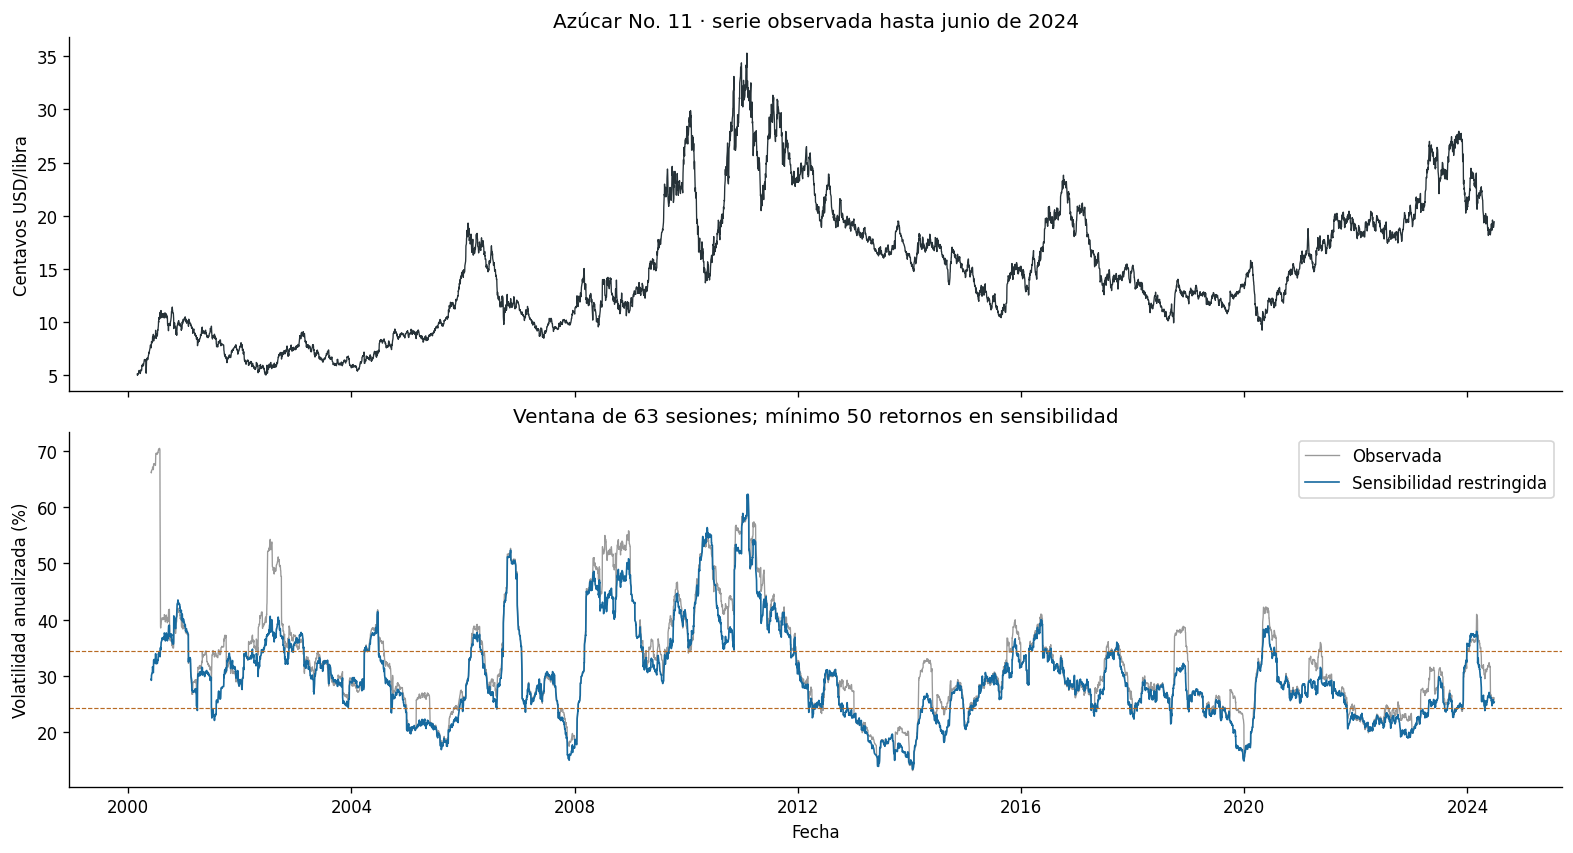

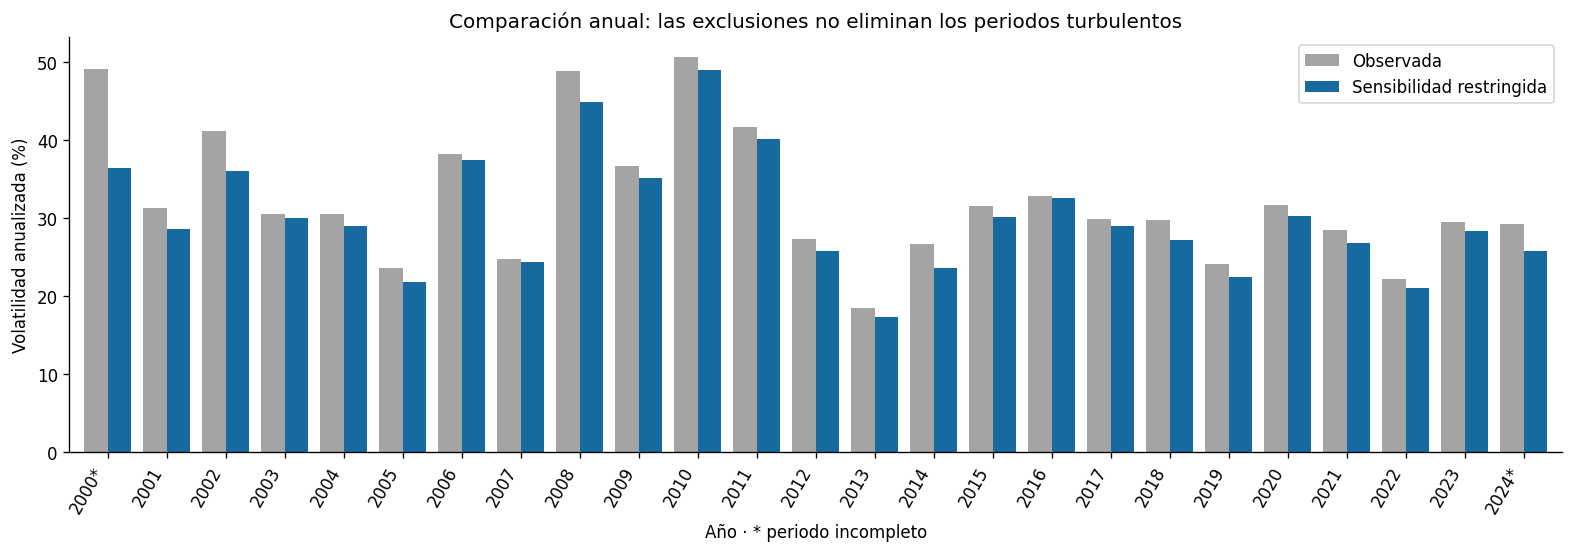

variante,observada,restringida
ano,,
2008,48.92,44.85
2010,50.71,49.02
2011,41.73,40.17
2020,31.63,30.27
2022,22.18,21.07
2023,29.48,28.38
2024,29.25,25.81


In [3]:
fig,ax=plt.subplots(2,1,figsize=(13,7),sharex=True,layout="constrained")
ax[0].plot(p.date,p.close,color="#263238",lw=.8)
ax[0].set(title="Azúcar No. 11 · serie observada hasta junio de 2024",ylabel="Centavos USD/libra")
ax[1].plot(p.date,p.vol_63_observada_pct,color="#999999",lw=.8,label="Observada")
ax[1].plot(p.date,p.vol_63_restringida_pct,color="#176a9f",lw=1,label="Sensibilidad restringida")
for lim in decision["limites_estados_63_pct"]:
    ax[1].axhline(lim,color="#b86b24",lw=.7,ls="--")
ax[1].set(ylabel="Volatilidad anualizada (%)",xlabel="Fecha",title="Ventana de 63 sesiones; mínimo 50 retornos en sensibilidad")
ax[1].legend(loc="upper right")
fig.savefig(out/"precio_y_volatilidad.png",dpi=160)
plt.show()

vista=anuales.pivot(index="ano",columns="variante",values="vol_anualizada_pct")
fig,ax=plt.subplots(figsize=(13,4.5),layout="constrained")
vista[["observada","restringida"]].plot.bar(ax=ax,color=["#a4a4a4","#176a9f"],width=.8)
ax.set_xticklabels([f"{a}*" if a in [2000,2024] else str(a) for a in vista.index],rotation=60,ha="right")
ax.set(ylabel="Volatilidad anualizada (%)",xlabel="Año · * periodo incompleto",title="Comparación anual: las exclusiones no eliminan los periodos turbulentos")
ax.legend(["Observada","Sensibilidad restringida"])
fig.savefig(out/"volatilidad_anual.png",dpi=160)
plt.show()
display(vista.loc[[2008,2010,2011,2020,2022,2023,2024]].round(2))

## Estados descriptivos de volatilidad

Se usan los cuartiles históricos de volatilidad móvil restringida a 63 sesiones: **baja ≤24.35 %, intermedia hasta 34.35 % y alta >34.35 %**. El 25/50/25 % aproximado de sesiones resulta del diseño; no demuestra tres regímenes naturales.

Los límites se calculan sobre toda la historia para describirla. No son umbrales calibrados para un test futuro. La volatilidad móvil utiliza datos hasta cada fecha, pero sus ventanas solapadas inducen persistencia; un episodio largo no equivale a un solo choque económico.

El tramo alto más largo abarca 2009-09-10 a 2011-11-16 (552 sesiones); 2008 y 2010–2011 muestran riesgo elevado también en la volatilidad anual. Cambiar de 63 a 21 sesiones modifica aproximadamente 30.89 % de los estados comparables. Al comparar observada/restringida con los mismos límites de 63 sesiones, cambia 13.71 %. Hay dependencia del horizonte y de la continuidad.

La correlación lineal del retorno con la sesión anterior es cercana a cero en la sensibilidad (0.0014), mientras la de su magnitud es 0.0971. Es evidencia descriptiva modesta de agrupación de magnitudes, no significancia certificada, predictibilidad comercial ni prueba de causalidad.

In [4]:
display(pd.read_csv(out/"perfiles_estados.csv").round(3))
display(episodios[episodios.estado.eq("alta")].nlargest(8,"sesiones"))
comunes=p.estado_21.ne("sin_cobertura") & p.estado_63.ne("sin_cobertura")
print("Cambio 21/63 (%):",100*p.loc[comunes,"estado_21"].ne(p.loc[comunes,"estado_63"]).mean())
print("Cambio observada/restringida 63 (%):",decision["cambio_estado_por_restriccion_pct"])
display(pd.read_csv(out/"dependencia_retornos.csv").round(5))

,estado_63,sesiones,vol_mediana_pct,precio_mediano_cent_lb
0,alta,1508,39.107,14.015
1,baja,1508,21.383,16.470
2,intermedia,3014,28.607,13.205
3,sin_cobertura,67,NaN,6.180


,estado,inicio,fin,sesiones,vol_mediana_pct
58,alta,2009-09-10,2011-11-16,552,41.938261
54,alta,2008-03-06,2009-03-16,259,44.637182
4,alta,2000-07-31,2001-01-29,125,37.784026
16,alta,2002-06-06,2002-10-15,91,37.393210
48,alta,2006-09-21,2007-01-18,80,48.184164
88,alta,2016-02-23,2016-05-20,63,37.028558
32,alta,2004-04-19,2004-06-25,48,37.390733
150,alta,2023-12-28,2024-03-07,48,37.118533


Cambio 21/63 (%): 30.892143808255657
Cambio observada/restringida 63 (%): 13.714759535655057


,variante,rezago_sesiones,transformacion,n_pares,correlacion
0,observada,1,retorno,6095,-0.01855
1,observada,1,absoluto,6095,0.14545
2,observada,5,retorno,6091,-0.01430
3,observada,5,absoluto,6091,0.09787
4,restringida,1,retorno,5589,0.00136
5,restringida,1,absoluto,5589,0.09715
6,restringida,5,retorno,5406,-0.00325
7,restringida,5,absoluto,5406,0.11335


## Extremos: movimiento real, posible enlace y dato pendiente de confirmar

El P99 de |log-retorno| observado es 6.654 %, con 61 marcas. De ellas, 27 se apartan en la sensibilidad por sus reglas previas de calidad/calendario; no se declaran falsas. La sensibilidad tiene su propio P99 de 5.881 % y 58 marcas. Estos percentiles etiquetan rareza, no errores ni probabilidades de crisis.

- **28-04-2000 / 01-05-2000:** −16.50 % / +26.55 % simples, alrededor de frontera contractual y con volumen cero el primer día. Son casos sospechosos de enlace/reporte, sin reparación exacta demostrable.
- **30-06-2008 / 01-07-2008:** cierre fuera del rango OHLC seguido de +13.95 % simple en otra frontera. No se atribuye íntegramente a un cambio económico de mercado.
- **11/12-11-2010:** 29.66→26.21 centavos/libra y −11.63 % el segundo día, sin las marcas de exclusión. La tabla contemporánea FNB publica 26.21 para Mar-11; Bloomberg permite reconstruir 29.66 como cierre previo de ese mismo vencimiento. Es corroboración puntual de nivel y caída, no certificación de toda la fuente ni identificación de su causa.
- **23-02-2016:** +11.02 % simple, permanece en la sensibilidad. Reuters documenta un fuerte repunte ese día, pero cotiza mayo e intradía; respalda el contexto, sin confirmar exactamente el cierre 14.00 ni ese porcentaje del CSV.

Se conservan todos los valores. La ausencia de marcas no prueba que los demás retornos sean del mismo contrato.

Extremos observados/restringidos: 61 58
Extremos observados apartados: 27


C:\Users\user\AppData\Local\Temp\ipykernel_21908\2923658838.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(p.loc[p.retorno_log.abs().nlargest(12).index,["date","close","retorno_simple_pct","proxy_enlace","volumen_cero","admisible_sensibilidad"]].round(3))


,date,close,retorno_simple_pct,proxy_enlace,volumen_cero,admisible_sensibilidad
42,2000-05-01,6.53,26.550,True,False,False
41,2000-04-28,5.16,-16.505,True,True,False
579,2002-07-01,5.16,-12.690,True,False,False
2077,2008-07-01,13.72,13.953,True,False,False
2675,2010-11-12,26.21,-11.632,False,False,True
2141,2008-10-01,13.93,12.702,True,False,False
2003,2008-03-17,12.09,-10.709,False,False,True
4655,2018-10-01,11.61,11.420,True,False,False
2707,2010-12-30,30.38,-10.198,False,False,True
2747,2011-03-01,29.26,-9.997,True,False,False


,fecha,precio_referencia_cent_lb,contrato,fuente,alcance,date,close,diferencia_cent_lb
0,2010-11-11,29.66,Mar-11,f007,cierre previo implícito: 27.98 + caída intradí...,2010-11-11,29.660000,-1.525879e-07
1,2010-11-12,26.21,Mar-11,f005,tabla ICE Sugar Futures de informe FNB; cotejo...,2010-11-12,26.209999,-9.155273e-07


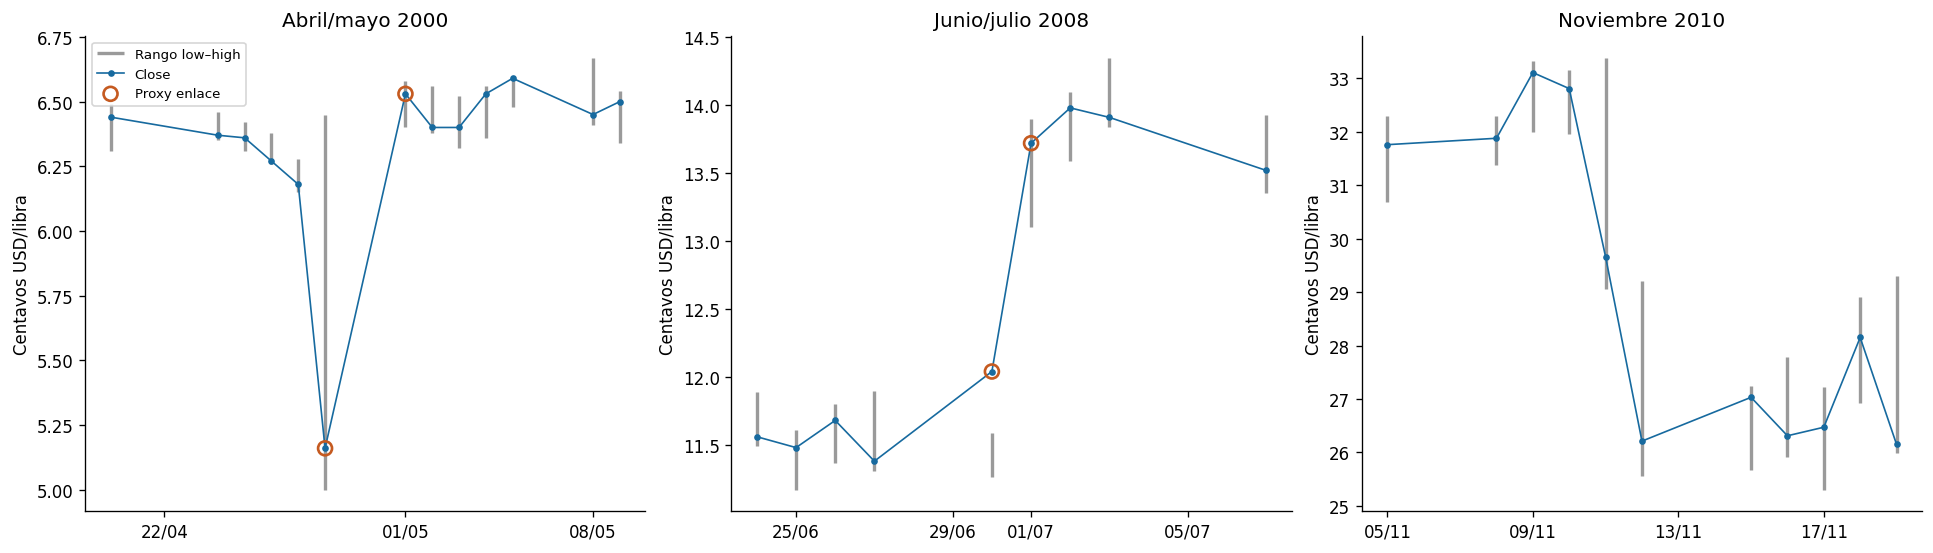

Variación de valor bruto por contrato largo de 112000 lb (USD): -3864.0008544921875


In [5]:
print("Extremos observados/restringidos:",p.extremo_p99_observado.sum(),p.extremo_p99_restringido.sum())
print("Extremos observados apartados:",int((p.extremo_p99_observado & ~p.admisible_sensibilidad).sum()))
display(p.loc[p.retorno_log.abs().nlargest(12).index,["date","close","retorno_simple_pct","proxy_enlace","volumen_cero","admisible_sensibilidad"]].round(3))
display(pd.read_csv(out/"contraste_externo.csv"))

fig,axes=plt.subplots(1,3,figsize=(16,4.5),layout="constrained")
casos=[("2000-04-20","2000-05-09","Abril/mayo 2000"),("2008-06-24","2008-07-07","Junio/julio 2008"),("2010-11-05","2010-11-19","Noviembre 2010")]
for ax,(inicio,fin,titulo) in zip(axes,casos):
    g=p[p.date.between(inicio,fin)]
    ax.vlines(g.date,g.low,g.high,color="#9a9a9a",lw=2,label="Rango low–high")
    ax.plot(g.date,g.close,"o-",ms=3,color="#176a9f",lw=1,label="Close")
    m=g.proxy_enlace
    ax.scatter(g.loc[m,"date"],g.loc[m,"close"],s=70,facecolors="none",edgecolors="#c55a20",lw=1.6,label="Proxy enlace",zorder=3)
    ax.set(title=titulo,ylabel="Centavos USD/libra")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3,maxticks=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
axes[0].legend(fontsize=8,loc="upper left")
fig.savefig(out/"contextos_extremos.png",dpi=160)
plt.show()

f=p.set_index("date")
caida=float(f.loc["2010-11-12","close"]-f.loc["2010-11-11","close"])
print("Variación de valor bruto por contrato largo de 112000 lb (USD):",caida*112000/100)

## Evaluación gerencial y alcance de la verificación

**Resultado:** hay riesgo de precio importante y heterogéneo. La volatilidad anualizada cambia al retirar retornos sospechosos, pero siguen periodos turbulentos y caídas grandes corroboradas puntualmente. El CSV mezcla una referencia continua sin linaje suficiente para certificar todos sus movimientos como variaciones del mismo contrato.

**Decisión:** incorporar escenarios adversos de precio al presupuesto y revisar exposición de ventas frente a compromisos de costos. El riesgo persiste en las vistas completa/restringida y justifica priorizar protección del margen, sin fijar instrumentos o proporciones de cobertura con este archivo. Antes de usarla para calibrar límites comerciales o evaluar coberturas, hacen falta identificadores y liquidaciones por vencimiento, precios simultáneos al cambio y reglas de ajuste del proveedor. No asignar automáticamente un salto a clima, oferta, demanda o especulación.

**Impacto ilustrativo:** un centavo de USD/libra equivale a USD 1,120 por contrato de 112,000 lb. La caída corroborada de aproximadamente 3.45 centavos representa USD 3,864 de cambio bruto para una posición larga de un contrato. No incorpora comisiones, diferencial físico, moneda, calendario comercial ni estructura real del ingenio; no estima una pérdida de Santa Ana ni prescribe una cobertura.

**Certeza:** alta sobre fórmulas, conservación y anomalías internas detectadas; parcial sobre continuidad y movimientos de mercado. La sensibilidad no certifica una serie limpia. Los estados dependen del horizonte y límites descriptivos, sin validación predictiva. Se mantiene pendiente la verificación completa de cierre/liquidación y calendario histórico por contrato.

Evidencia en `outputs/serie3_precios/`: datos/marcas, retornos apartados con ambos extremos y motivo, sensibilidad, volatilidad anual, estados/episodios, extremos, contrastes externos, figuras y huella de fuente. Cinco pruebas específicas reconstruyen cálculos por otra ruta; no certifican precios que no se han contrastado externamente. Este notebook responde al inciso 2. El [notebook 16](16_pronostico_azucar_serie3.ipynb) desarrolla el pronóstico condicionado a la fuente; el [notebook 17](17_oferta_precio_serie3.ipynb) examina oferta y rezagos con límites causales.

El [fundamento económico y las decisiones de Serie III](../docs/conclusiones-serie-III.md#lectura-económica-y-decisiones) integra evidencia, teoría, recomendaciones y sus supuestos.